In [1]:
import os
# This line for the Windows
# os.add_dll_directory(r"C:\Users\PC\Desktop\openslide-win64-20230414\openslide-win64-20230414\bin")
import datastructure.dataset as dataset
import arguments.setting as setting

In [2]:
data_directories = ["/workspaces/METHnet_GBM_segmentation-main/MountData/GBM_HE_Hamamatsu_40x"]
working_directory = "../workdir/"
csv_file = "patients.csv"
qupath_project_file = "/workspaces/METHnet_GBM_segmentation-main/MountData/QuPath-Annotationen_Karen/project.qpproj"
s = setting.Setting(data_directories, csv_file, working_directory, qupath_project_file)
data = dataset.Dataset(s)

 B37-17_HE_Hamamatsu_40x.ndpi has no annotations!
 B42-17_HE_Hamamatsu_40x.ndpi has no annotations!
Initial 1560 patients
 B529-23 doesn't have a valid wsi(check bugi names)
 B420-21 doesn't have a valid wsi(check bugi names)
 B1867-21 doesn't have a valid wsi(check bugi names)
 B1388-22 doesn't have a valid wsi(check bugi names)
 B340-19 doesn't have a valid wsi(check bugi names)
 B637-23 doesn't have a valid wsi(check bugi names)
 B1000-13 doesn't have a valid wsi(check bugi names)
 B64-23 doesn't have a valid wsi(check bugi names)
 B259-19 doesn't have a valid wsi(check bugi names)
 B249-19 doesn't have a valid wsi(check bugi names)
 B174-21 doesn't have a valid wsi(check bugi names)
 B126-17 doesn't have a valid wsi(check bugi names)
 B47-17 doesn't have a valid wsi(check bugi names)
 B10-20 doesn't have a valid wsi(check bugi names)
 B1666-18 doesn't have a valid wsi(check bugi names)
 B1452-21 doesn't have a valid wsi(check bugi names)
 B1166-19 doesn't have a valid wsi(check bug

In [3]:
import numpy as np

def min_max_image(img):
    img_min = np.min(img, axis = (0, 1))
    img_max = np.max(img, axis = (0, 1))
    return (img - img_min) / (img_max - img_min)

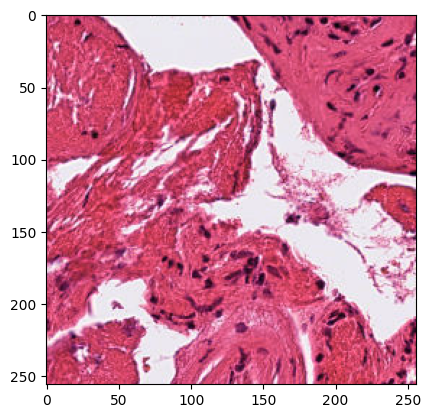

In [4]:
import matplotlib.pyplot as plt

patient = data.get_test_set()[0][0]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()
plt.imshow(min_max_image(wsi.tiles[0][0].get_image(wsi.image)))

In [5]:
project = wsi.get_qupath_project()

In [6]:
project.images[2].downsample_levels

recovering readonly from server.json


[{'downsample': 1.0, 'width': 130560, 'height': 105984},
 {'downsample': 2.0, 'width': 65280, 'height': 52992},
 {'downsample': 4.0, 'width': 32640, 'height': 26496},
 {'downsample': 8.0, 'width': 16320, 'height': 13248},
 {'downsample': 16.0, 'width': 8160, 'height': 6624},
 {'downsample': 32.0, 'width': 4080, 'height': 3312},
 {'downsample': 64.0, 'width': 2040, 'height': 1656},
 {'downsample': 128.0, 'width': 1020, 'height': 828},
 {'downsample': 256.0, 'width': 510, 'height': 414}]

FileNotFoundError: [Errno 2] No such file or directory: '/media/przybilla/Elements/Hamamatsu/GBM_HE_Hamamatsu_40x/B11-18_HE_Hamamatsu_40x.ndpi'

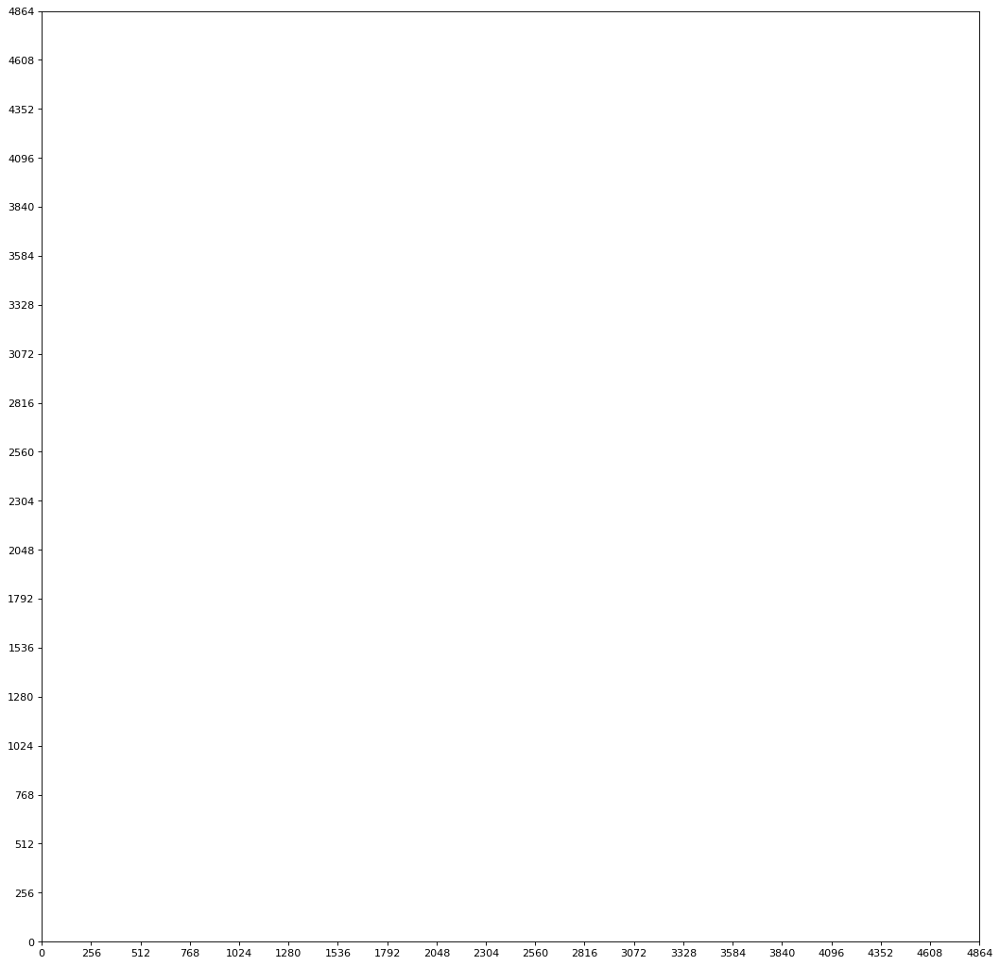

In [7]:
plt.figure(figsize=(16, 16), dpi=80)
major_ticks = np.arange(0, 5000, 256)
plt.xticks(major_ticks)
plt.yticks(major_ticks)
arr = project.get_tile(2, (32640 / 8 + 7000, 26496 / 8 + 9000), (5000, 5000), 2, ret_array = True)
plt.grid(which='both')
plt.imshow(arr)
plt.savefig("example_patches1.png")

In [8]:
from histomicstk.preprocessing.color_normalization import reinhard
from histomicstk.saliency.tissue_detection import (
    get_slide_thumbnail, get_tissue_mask)

In [9]:
n_classes = len(wsi.qupath_project.path_classes) - 1

for index, c in enumerate(wsi.qupath_project.path_classes[:-1]):
    print(f"Class {c.name} returned as the channel {(index - 1 - n_classes) % n_classes} in MOTHI")

Class Tumor returned as the channel 15 in MOTHI
Class Hirnparenchym returned as the channel 0 in MOTHI
Class Infiltrationszone returned as the channel 1 in MOTHI
Class Blutung returned as the channel 2 in MOTHI
Class Luftblasen returned as the channel 3 in MOTHI
Class Haare returned as the channel 4 in MOTHI
Class Falten returned as the channel 5 in MOTHI
Class Risse returned as the channel 6 in MOTHI
Class Nekrosen returned as the channel 7 in MOTHI
Class Pseudopalisaden returned as the channel 8 in MOTHI
Class Artefakt returned as the channel 9 in MOTHI
Class artifiziell verändertes Gewebe returned as the channel 10 in MOTHI
Class Nekrose und Blutung returned as the channel 11 in MOTHI
Class Pränekrose returned as the channel 12 in MOTHI
Class out of focus returned as the channel 13 in MOTHI
Class Filzstift returned as the channel 14 in MOTHI


ImageEntries(['B7-18_HE_Hamamatsu_40x.ndpi', 'B9-18_HE_Hamamatsu_40x.ndpi', 'B11-18_HE_Hamamatsu_40x.ndpi', 'B17-19_HE_Hamamatsu_40x.ndpi', 'B20-16_HE_Hamamatsu_40x.ndpi', 'B23-18_HE_Hamamatsu_40x.ndpi', 'B27-19_HE_Hamamatsu_40x.ndpi', 'B28-19_HE_Hamamatsu_40x.ndpi', 'B30-18_HE_Hamamatsu_40x.ndpi', 'B35-18_1_HE_Hamamatsu_40x.ndpi', 'B35-18_2_HE_Hamamatsu_40x.ndpi', 'B36-17_1_HE_Hamamatsu_40x.ndpi', 'B36-17_2_HE_Hamamatsu_40x.ndpi', 'B37-17_HE_Hamamatsu_40x.ndpi', 'B42-17_HE_Hamamatsu_40x.ndpi', 'B68-18_HE_Hamamatsu_40x.ndpi', 'B85-17_HE_Hamamatsu_40x.ndpi', 'B100-17_HE_Hamamatsu_40x.ndpi', 'B115-17_HE_Hamamatsu_40x.ndpi', 'B127-19_HE_Hamamatsu_40x.ndpi', 'B128-19_HE_Hamamatsu_40x.ndpi', 'B129-19_HE_Hamamatsu_40x.ndpi', 'B132-17_HE_Hamamatsu_40x.ndpi', 'B138-18_HE_Hamamatsu_40x.ndpi', 'B149-16_HE_Hamamatsu_40x.ndpi', 'B157-17_HE_Hamamatsu_40x.ndpi', 'B162-17_HE_Hamamatsu_40x.ndpi', 'B165-19_HE_Hamamatsu_40x.ndpi', 'B177-18_HE_Hamamatsu_40x.ndpi', 'B178-19_HE_Hamamatsu_40x.ndpi', 'B179-17_HE_Hamamatsu_40x.ndpi', 'B181-16_HE_Hamamatsu_40x.ndpi', 'B187-16_HE_Hamamatsu_40x.ndpi', 'B201-18_HE_Hamamatsu_40x.ndpi', 'B205-09_HE_Hamamatsu_40x.ndpi', 'B205-18_1_HE_Hamamatsu_40x.ndpi', 'B205-18_2_HE_Hamamatsu_40x.ndpi', 'B205-18_HE_Hamamatsu_40x.ndpi', 'B207-17_HE_Hamamatsu_40x.ndpi', 'B217-16_HE_Hamamatsu_40x.ndpi', 'B223-18_HE_Hamamatsu_40x.ndpi', 'B224-17_HE_Hamamatsu_40x.ndpi', 'B230-16_HE_Hamamatsu_40x.ndpi', 'B234-19_HE_Hamamatsu_40x.ndpi', 'B238-18_HE_Hamamatsu_40x.ndpi', 'B249-16_HE_Hamamatsu_40x.ndpi', 'B250-16_HE_Hamamatsu_40x.ndpi', 'B255-16_HE_Hamamatsu_40x.ndpi', 'B262-17_HE_Hamamatsu_40x.ndpi', 'B277-17_HE_Hamamatsu_40x.ndpi', 'B293-17_HE_Hamamatsu_40x.ndpi', 'B300-18_HE_Hamamatsu_40x.ndpi', 'B320-16_HE_Hamamatsu_40x.ndpi', 'B323-18_HE_Hamamatsu_40x.ndpi', 'B339-17_HE_Hamamatsu_40x.ndpi', 'B350-18_HE_Hamamatsu_40x.ndpi', 'B352-17_HE_Hamamatsu_40x.ndpi', 'B360-16_HE_Hamamatsu_40x.ndpi', 'B381-18_HE_Hamamatsu_40x.ndpi', 'B397-19_HE_Hamamatsu_40x.ndpi', 'B401-18_HE_Hamamatsu_40x.ndpi', 'B410-17_HE_Hamamatsu_40x.ndpi', 'B411-19_HE_Hamamatsu_40x.ndpi', 'B425-17_HE_Hamamatsu_40x.ndpi', 'B427-19_HE_Hamamatsu_40x.ndpi', 'B429-16_HE_Hamamatsu_40x.ndpi', 'B438-16_HE_Hamamatsu_40x.ndpi', 'B438-18_HE_Hamamatsu_40x.ndpi', 'B444-16_HE_Hamamatsu_40x.ndpi', 'B444-17_HE_Hamamatsu_40x.ndpi', 'B450-16_HE_Hamamatsu_40x.ndpi', 'B457-17_HE_Hamamatsu_40x.ndpi', 'B463-18_HE_Hamamatsu_40x.ndpi', 'B469-17_HE_Hamamatsu_40x.ndpi', 'B473-17_HE_Hamamatsu_40x.ndpi', 'B494-15_HE_Hamamatsu_40x.ndpi', 'B500-19_HE_Hamamatsu_40x.ndpi', 'B509-19_HE_Hamamatsu_40x.ndpi', 'B517-18_HE_Hamamatsu_40x.ndpi', 'B552-16_HE_Hamamatsu_40x.ndpi', 'B561-17_HE_Hamamatsu_40x.ndpi', 'B567-18_HE_Hamamatsu_40x.ndpi', 'B577-19_HE_Hamamatsu_40x.ndpi', 'B578-16_HE_Hamamatsu_40x.ndpi', 'B620-16_HE_Hamamatsu_40x.ndpi', 'B626-17_1_HE_Hamamatsu_40x.ndpi', 'B626-17_2_HE_Hamamatsu_40x.ndpi', 'B628-17_HE_Hamamatsu_40x.ndpi', 'B631-19_HE_Hamamatsu_40x.ndpi', 'B640-18_HE_Hamamatsu_40x.ndpi', 'B645-17_HE_Hamamatsu_40x.ndpi', 'B654-16_HE_Hamamatsu_40x.ndpi', 'B662-17_HE_Hamamatsu_40x.ndpi', 'B668-18_1_HE_Hamamatsu_40x.ndpi', 'B668-18_2_HE_Hamamatsu_40x.ndpi', 'B675-16_HE_Hamamatsu_40x.ndpi', 'B681-16_HE_Hamamatsu_40x.ndpi', 'B692-17_HE_Hamamatsu_40x.ndpi', 'B694-17_HE_Hamamatsu_40x.ndpi', 'B699-18_HE_Hamamatsu_40x.ndpi', 'B703-19_HE_Hamamatsu_40x.ndpi', 'B704-16_HE_Hamamatsu_40x.ndpi', 'B724-16_HE_Hamamatsu_40x.ndpi', 'B724-17_HE_Hamamatsu_40x.ndpi', 'B729-18_HE_Hamamatsu_40x.ndpi', 'B731-15_HE_Hamamatsu_40x.ndpi', 'B743-18_HE_Hamamatsu_40x.ndpi', 'B745-17_HE_Hamamatsu_40x.ndpi', 'B757-18_HE_Hamamatsu_40x.ndpi', 'B759-18_HE_Hamamatsu_40x.ndpi', 'B761-17_HE_Hamamatsu_40x.ndpi', 'B761-19_HE_Hamamatsu_40x.ndpi', 'B769-17_HE_Hamamatsu_40x.ndpi', 'B773-18_HE_Hamamatsu_40x.ndpi', 'B776-17_HE_Hamamatsu_40x.ndpi', 'B777-17_HE_Hamamatsu_40x.ndpi', 'B829-18_HE_Hamamatsu_40x.ndpi', 'B831-16_HE_Hamamatsu_40x.ndpi', 'B841-18_HE_Hamamatsu_40x.ndpi', 'B850-17_1_HE_Hamamatsu_40x.ndpi', 'B852-17_HE_Hamamatsu_4
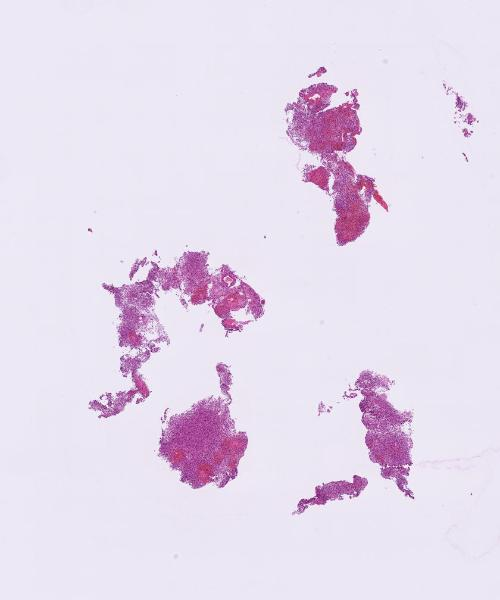
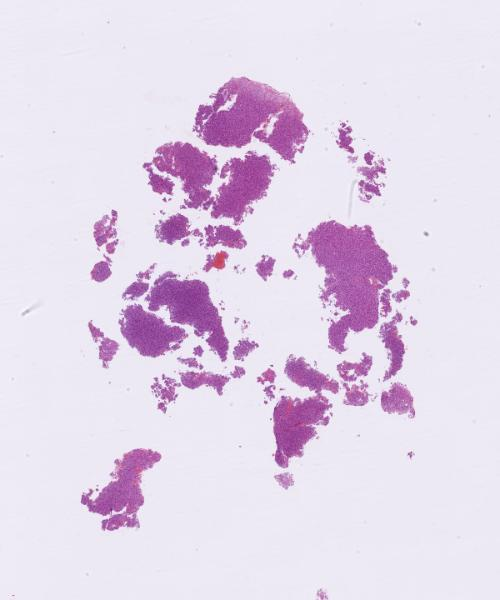
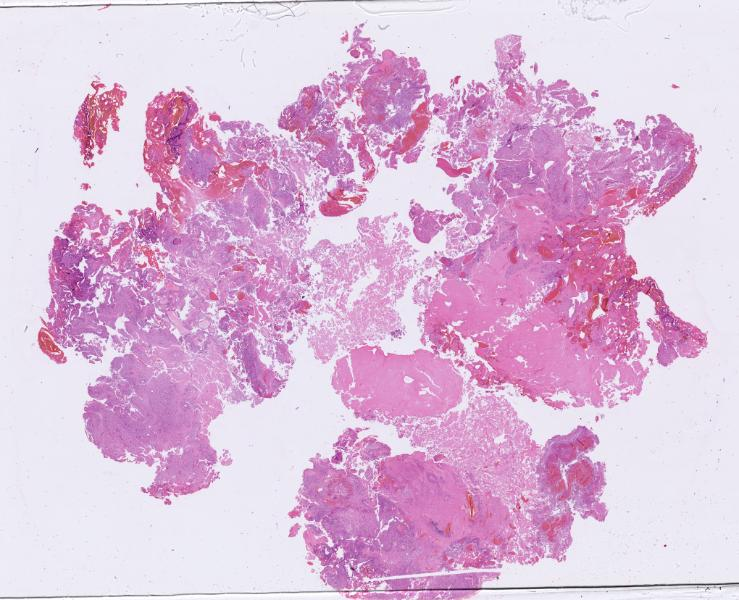
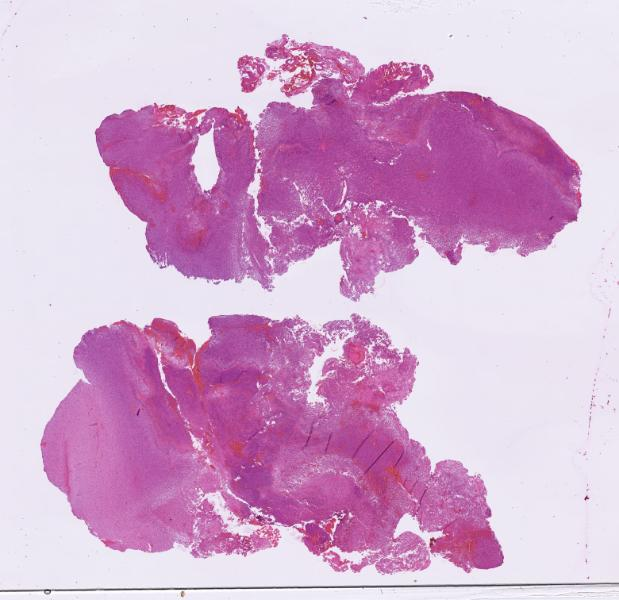
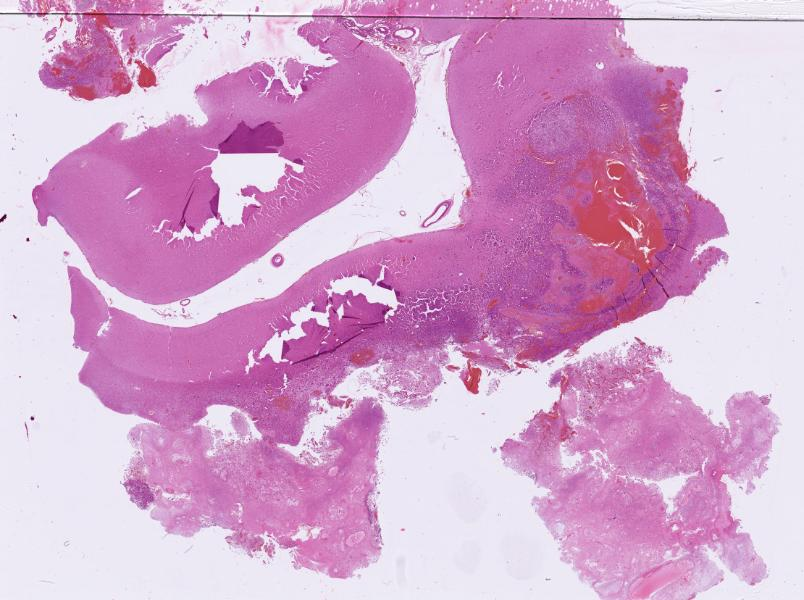
...
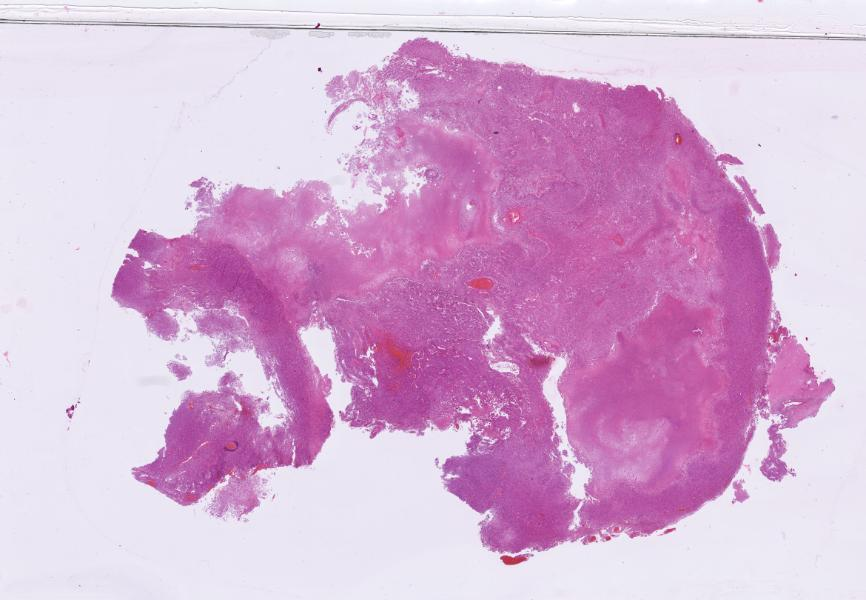
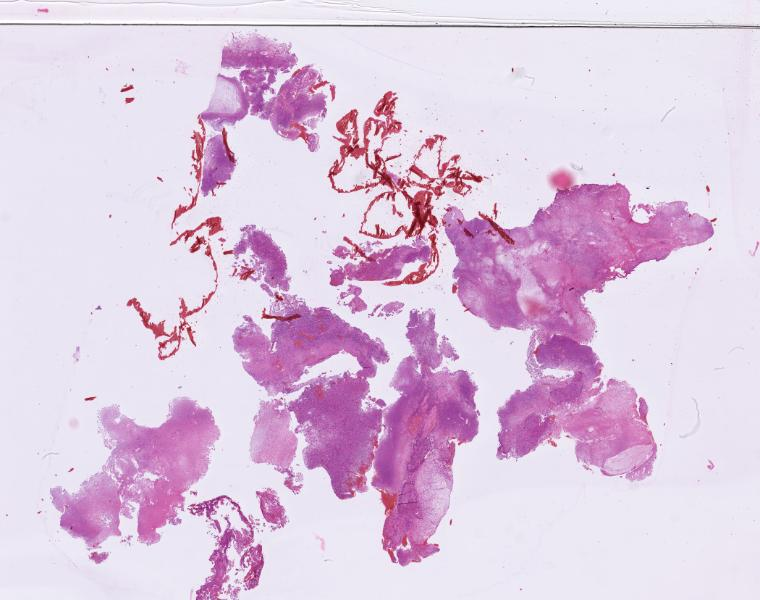
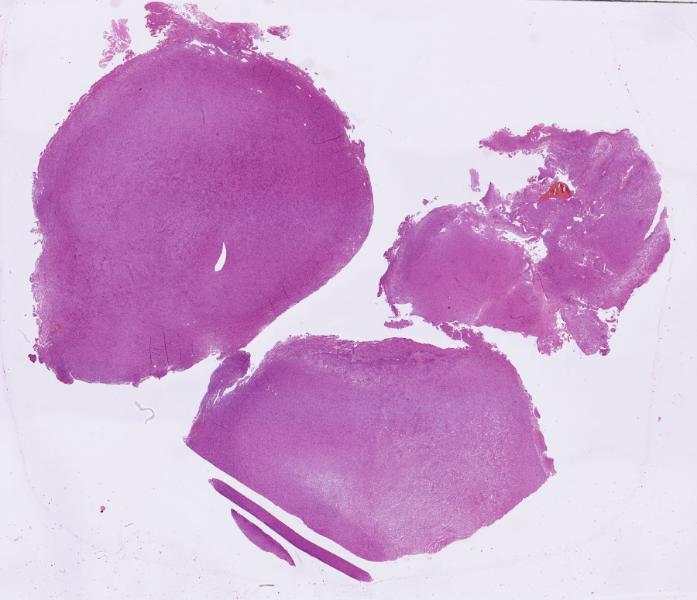
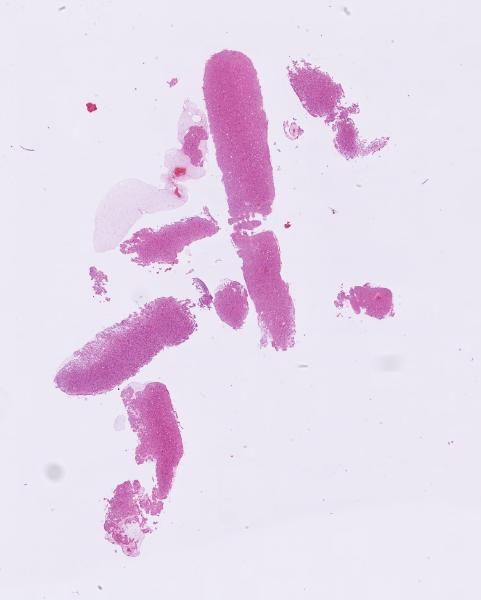
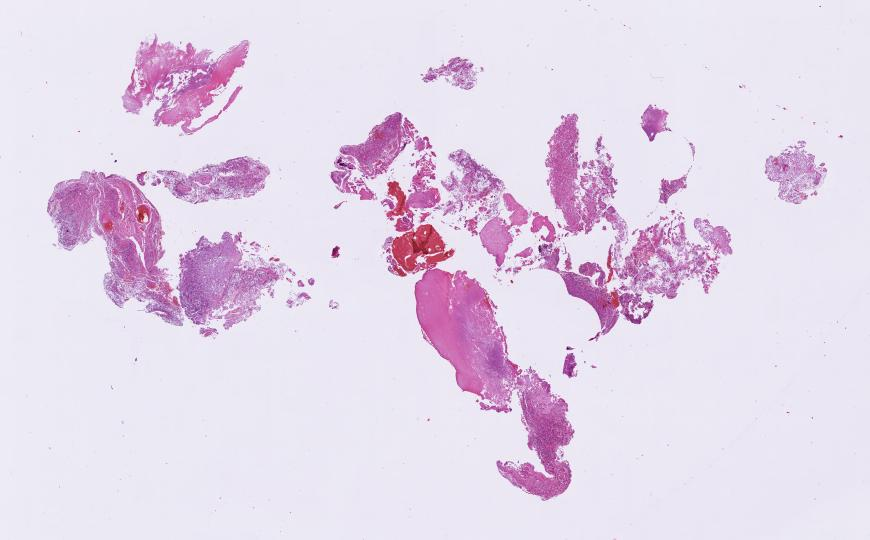

In [10]:
project.images

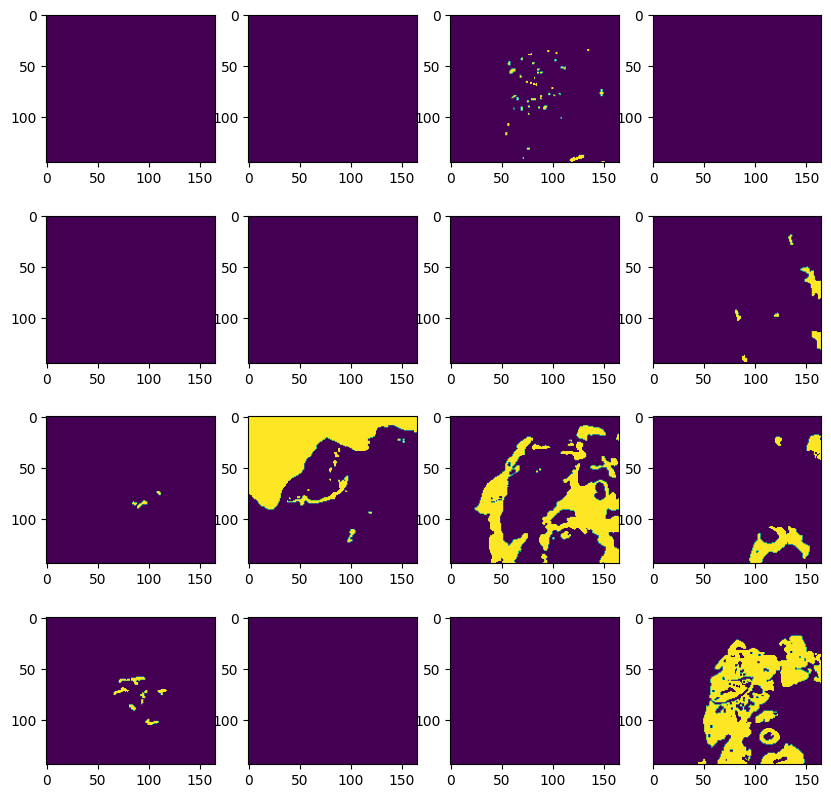

In [11]:
# NOTE: MOTHI shifts the given classes by one to the left. It caused me wasting too much time and I wanted to show it here
# You can see that tumor is in the first list in the upper list. 
# Also you can check the annotations of the B128-19_HE_Hamamatsu_40x.ndpi from the QuPath project
# But here, it is retrieved as the last element :/

arr = wsi.qupath_project.get_tile_annot_mask(18, (0, 0), (165, 144), 8, multichannel = True)

fig, ax = plt.subplots(4, 4, figsize = (10, 10))
for i in range(16):
    ax[i // 4][i % 4].imshow(arr[i])

In [12]:
patient = data.get_train_set()[0][0]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()

tiles_with_masks = []
label_index = 3 # Class Blutung, since it is not multichannel, it is not shifted to the left

for tile in wsi.tiles[0]:
    annotation, _ = tile.get_annotation(wsi)
    if (annotation == label_index + 1).any():
        tiles_with_masks.append([tile, annotation])

In [13]:
wsi.identifier

'B1114-17'

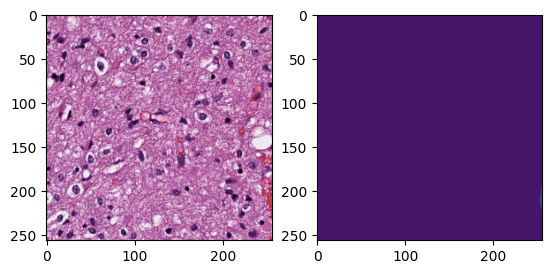

In [14]:
# Explicit example of we are getting the correct tiles

fig, axes = plt.subplots(1, 2)
axes[0].imshow(min_max_image(tiles_with_masks[0][0].get_image(wsi.image)))
axes[1].imshow(tiles_with_masks[0][1], vmin = 0, vmax = 17) # This tile has the unsure class, we will ignore it during training

In [15]:
patient = data.get_train_set()[0][2]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()

tiles_with_masks = []
label_index = 6 # Class Falten 

for tile in wsi.tiles[0]:
    annotation, _ = tile.get_annotation(wsi)
    if (annotation == label_index + 1).any():
        tiles_with_masks.append([tile, annotation])

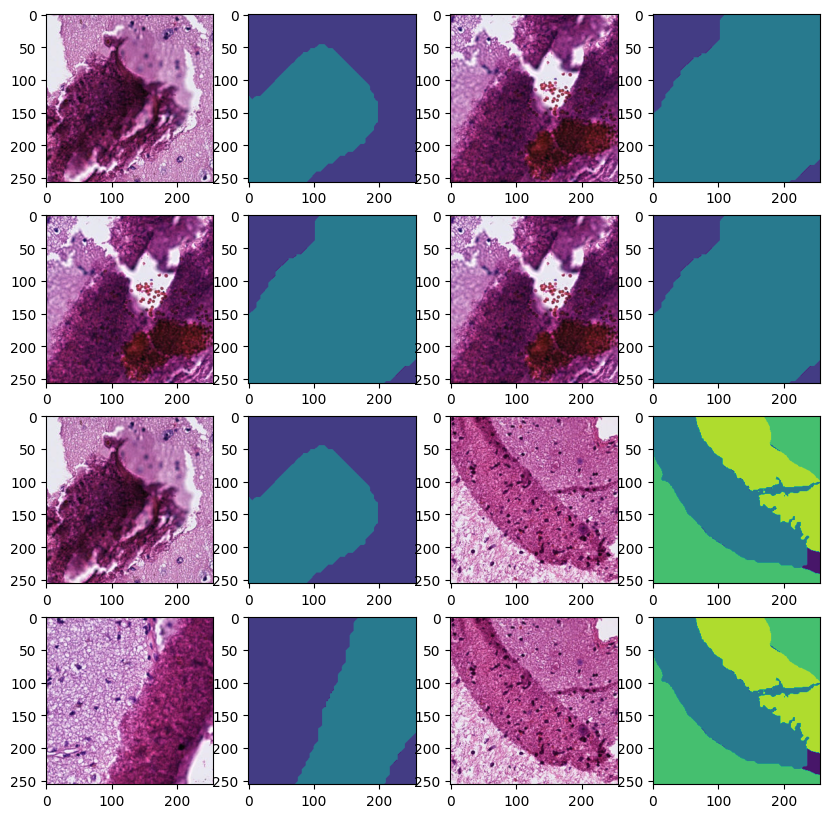

In [16]:
import random

fig, ax = plt.subplots(4, 4, figsize = (10, 10))
for i in range(4):
    tile1 = random.choice(tiles_with_masks)[0]
    tile2 = random.choice(tiles_with_masks)[0]
    ax[i][0].imshow(min_max_image(tile1.get_image(wsi.image)))
    ax[i][1].imshow(tile1.get_annotation(wsi)[0], vmin = 0, vmax = 17)
    ax[i][2].imshow(min_max_image(tile2.get_image(wsi.image)))
    ax[i][3].imshow(tile2.get_annotation(wsi)[0], vmin = 0, vmax = 17)

In [17]:
from pathlib import Path
import os

def update_qupath_paths(qupath_project, file_folder_path, delete_not_found = False):
    uri2uri = {}
    images = os.listdir(file_folder_path)
    to_be_deleted = []
    for image in qupath_project.images:
        if image.image_name in images:
            old_path = image.uri
            new_path = "file:/" + os.path.join(file_folder_path, image.image_name).replace("\\", "/")
            uri2uri[old_path] = new_path
            print(f"Path of the {image.image_name} has been changed!")
        elif delete_not_found:
            to_be_deleted.append(image)
            print(f"{image.image_name} has been deleted!")
    qupath_project.update_image_paths(uri2uri = uri2uri)
    for image in to_be_deleted:
        qupath_project.remove_image(image)
    qupath_project.save()

In [18]:
from mothi.tiling_projects import QuPathTilingProject
EXAMPLE_PROJECT = "/workspaces/METHnet_GBM_segmentation-main/MountData/QuPath-Annotationen_Karen/project.qpproj"
qp_project = QuPathTilingProject(EXAMPLE_PROJECT, mode = "r+")

In [ ]:
# WARNING DO NOT RUN THIS, IT UPDATES THE QUPATH PROJECT ACCORDING TO GIVEN FOLDER
# update_qupath_paths(qp_project, r"C:\Users\PC\Desktop\Max_Pathology\hamamatsu", delete_not_found = True)

In [19]:
# Following part should be changed. Please use the infer_dataset.py for the inference

from datastructure import dataset_torch
import torch
import numpy as np

@torch.no_grad()
def infer_qupath(img_id, model, qupath_project, norm_function = None, level = 2, 
                 n_channels = 1, patch_size = 256, device = "cpu"):
    image = qupath_project.images[img_id]
    downsample, width, height = image.downsample_levels[level].values()
    max_width, max_height = image.width, image.height
    annotations = np.zeros((height, width, n_channels))
    tile_arr = []
    for x in range(0, width, patch_size):
        for y in range(0, height, patch_size):
            tile_width = min(patch_size, width - x)
            tile_height = min(patch_size, height - y)
            tile = qupath_project.get_tile(img_id, (x * (2 ** level), y * (2 ** level)), 
                                           size = (tile_width,
                                                   tile_height),
                                           downsample_level = level)
            tile_arr.append(tile)
            if norm_function:
                tile = norm_function(tile)
            tile_padded = np.zeros((patch_size, patch_size, tile.shape[2]), dtype = np.float32)
            tile_padded[:tile.shape[0], :tile.shape[1]] = tile
            tile_model_sample = torch.tensor(np.transpose(tile_padded[None], [0, 3, 1, 2]), dtype = torch.float).to(device)
            inter = model(tile_model_sample).cpu().numpy()
            logits = inter[0]
            annotations[y : y + tile_height, x : x + tile_width] = logits.argmax(axis = 0).astype(int)[:tile_height, :tile_width, None]
            tile_arr.append(tile_padded)
    return image, annotations, tile_arr

In [20]:
from datastructure import dataset_torch

targets = s.get_network_setting().get_targets()
print(targets)
annotation_threshold = s.get_network_setting().get_annotation_threshold()
n_classes = len(targets)

dataset = dataset_torch.PathologyDataset(data.get_train_set(), False, s.get_data_setting().get_patch_size(),
                                                   targets, annotation_threshold)

n = len(dataset)

carr = np.zeros(n_classes)
indexes = np.arange(0, n, 1)
np.random.shuffle(indexes)
for i in range(n):
    _, y = dataset[indexes[i]]
    for c in range(n_classes):
        carr[c] += (y == c).sum()
    if not i % 1000 and i != 0:
        print(f"{i}: ", end = "")
        for c in carr / carr.sum():
            print(f"{c:.3f}", end = " ")
        print()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
1000: 0.088 0.500 0.000 0.073 0.008 0.000 0.000 0.001 0.000 0.097 0.000 0.004 0.173 0.032 0.021 0.003 0.000 
2000: 0.086 0.489 0.000 0.066 0.010 0.000 0.000 0.001 0.000 0.102 0.002 0.003 0.176 0.035 0.024 0.005 0.000 
3000: 0.087 0.488 0.000 0.064 0.011 0.000 0.000 0.001 0.000 0.106 0.002 0.003 0.174 0.033 0.025 0.005 0.000 
4000: 0.092 0.485 0.000 0.066 0.011 0.000 0.000 0.002 0.000 0.102 0.003 0.003 0.177 0.033 0.023 0.005 0.000 
5000: 0.093 0.479 0.000 0.068 0.012 0.000 0.000 0.002 0.000 0.103 0.003 0.004 0.176 0.033 0.023 0.005 0.000 
6000: 0.093 0.477 0.000 0.069 0.012 0.000 0.000 0.002 0.000 0.104 0.003 0.004 0.176 0.033 0.021 0.005 0.000 
7000: 0.092 0.481 0.000 0.067 0.012 0.000 0.000 0.002 0.000 0.105 0.003 0.004 0.175 0.033 0.022 0.005 0.000 
8000: 0.093 0.481 0.000 0.069 0.011 0.000 0.000 0.002 0.000 0.104 0.003 0.004 0.174 0.033 0.021 0.005 0.000 
9000: 0.092 0.485 0.000 0.069 0.012 0.000 0.000 0.002 0.000 0.101 0.0

In [21]:
if 0 in targets:
    classes = ["Background"] + [dataset.classes[i - 1] for i in targets[1:]]
else:
    classes = [dataset.classes[i - 1] for i in targets]
t = ""
for i in range(len(carr)):
    print(f"Class {classes[i]} has {carr[i]} pixels and %{carr[i] * 100 / carr.sum():.2f} of the dataset")
    t += f"Class {classes[i]} has {carr[i]} pixels and %{carr[i] * 100 / carr.sum():.2f} of the dataset"
    if i != len(carr) - 1:
        t += "\n"

Class Background has 2481514833.0 pixels and %9.67 of the dataset
Class Tumor has 12239311740.0 pixels and %47.72 of the dataset
Class Hirnparenchym has 0.0 pixels and %0.00 of the dataset
Class Infiltrationszone has 1808058498.0 pixels and %7.05 of the dataset
Class Blutung has 311561271.0 pixels and %1.21 of the dataset
Class Luftblasen has 553261.0 pixels and %0.00 of the dataset
Class Haare has 573214.0 pixels and %0.00 of the dataset
Class Falten has 56007464.0 pixels and %0.22 of the dataset
Class Risse has 7063.0 pixels and %0.00 of the dataset
Class Nekrosen has 2600473244.0 pixels and %10.14 of the dataset
Class Pseudopalisaden has 65675979.0 pixels and %0.26 of the dataset
Class Artefakt has 89127071.0 pixels and %0.35 of the dataset
Class artifiziell verändertes Gewebe has 4550197599.0 pixels and %17.74 of the dataset
Class Nekrose und Blutung has 829168562.0 pixels and %3.23 of the dataset
Class Pränekrose has 505751404.0 pixels and %1.97 of the dataset
Class out of focus h

In [22]:
print(t, file = open("classes_train_17.txt", "w"))